## Group G:
1. [teammate]
2. Akhmad Fauzi Nurulhamzah

## Consuming data using Kafka and Visualise (20%)
In this task, we will implement an Apache Kafka consumer to consume the data from Part 2.  
  
Important:   
-	In this part, Kafka consumers are used to consume the streaming data published from task 2.8.

In [1]:
# ==============================
# Kafka Consumer Setup
# ==============================

from kafka import KafkaConsumer
import json
import os
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import clear_output
from collections import defaultdict

DATA_DIR = "dataset"

KAFKA_BOOTSTRAP = "kafka:9092"

TOPIC_6B = "building_6h_energy"
TOPIC_6C = "site_daily_energy"

print("Kafka consumer configuration ready.")

Kafka consumer configuration ready.


1.	Load the new meters CSV file into a data frame.

The new_meters.csv file is loaded into a Pandas DataFrame. This dataset contains the actual metered energy consumption that will later be compared with the predicted energy received from Kafka.

In [2]:
# ==============================
# 1. Load new_meters.csv
# ==============================

METERS_CSV = os.path.join(DATA_DIR, "new_meters.csv")
meters = pd.read_csv(METERS_CSV)

print(
    "meters rows:", len(meters),
    "| buildings:", meters["building_id"].nunique(),
    "| meter types:", sorted(meters["meter_type"].unique())
)

meters.head()

meters rows: 6391082 | buildings: 449 | meter types: ['c', 'e', 'h', 's']


,building_id,meter_type,ts,value,row_id
0,163,c,2022-01-01 00:00:00.000,4.5719,3
1,170,c,2022-01-01 00:00:00.000,11.2891,8
2,171,c,2022-01-01 00:00:00.000,0.0000,9
3,172,c,2022-01-01 00:00:00.000,0.0000,10
4,174,c,2022-01-01 00:00:00.000,52.8583,12


2.	Plot two diagrams to show data from 6b and 6c. You are free to choose the type of plot.

### Visualisation Approach

The outputs from Task 2.8 are consumed from Kafka and stored in Pandas
DataFrames for visualisation. Output 6b contains predicted energy for each
building and 6-hour interval, while output 6c contains the daily predicted
total energy for each site.

For 6b, the mean predicted energy across buildings is calculated for each
6-hour period to compare demand patterns throughout the day. For 6c, the
latest available date is selected to compare predicted daily energy demand
across sites.

In [3]:
# ==============================
# 2. Consume 6b and 6c from Kafka
# ==============================

consumer = KafkaConsumer(
    TOPIC_6B,
    TOPIC_6C,
    bootstrap_servers=[KAFKA_BOOTSTRAP],
    auto_offset_reset="earliest",
    enable_auto_commit=False,
    consumer_timeout_ms=10000,
    value_deserializer=lambda x: json.loads(x.decode("utf-8"))
)

latest_6b = {}
latest_6c = {}

print("Consuming available predictions from Kafka...")

for msg in consumer:
    record = msg.value

    if msg.topic == TOPIC_6B:
        key = (
            record["building_id"],
            record["interval_start"]
        )
        latest_6b[key] = record

    elif msg.topic == TOPIC_6C:
        key = (
            record["site_id"],
            record["date"]
        )
        latest_6c[key] = record

consumer.close()

# Convert consumed records to Pandas DataFrames
pred_building = pd.DataFrame(latest_6b.values())
pred_site = pd.DataFrame(latest_6c.values())

print(
    f"Kafka consumption complete — "
    f"6b: {len(pred_building)} records, "
    f"6c: {len(pred_site)} records."
)

Consuming available predictions from Kafka...


/tmp/ipykernel_967871/2292512069.py:5: DeprecationWarning: value_deserializer does not implement kafka.serializer.Deserializer
  consumer = KafkaConsumer(


Kafka consumption complete — 6b: 646044 records, 6c: 5760 records.


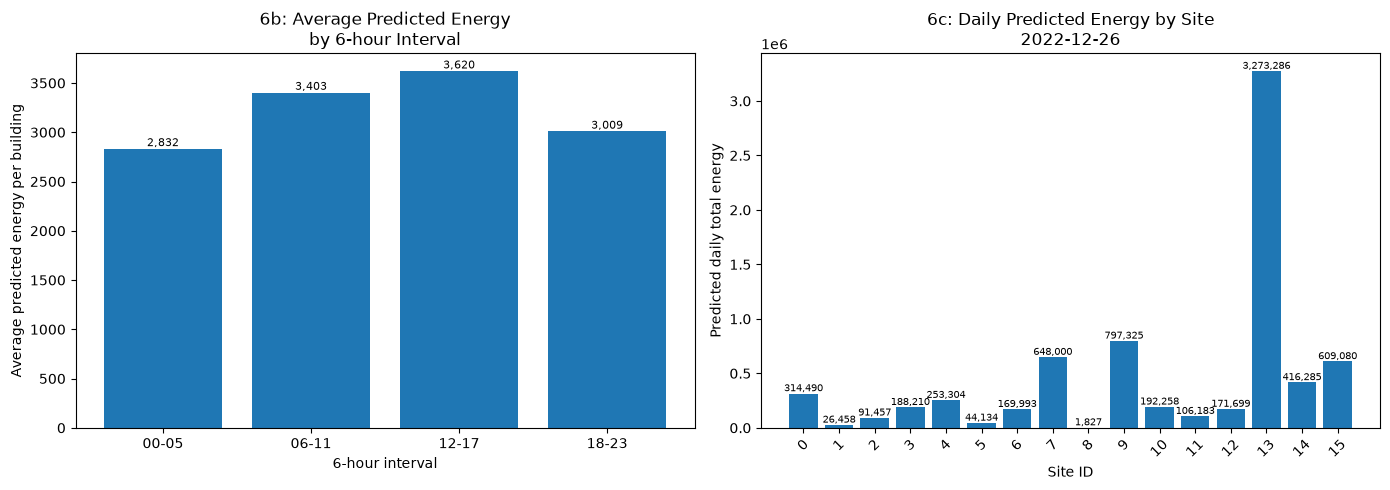

In [4]:
# ==============================
# Plot Task 6b and 6c outputs
# ==============================

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# ------------------------------
# 6b: Building-level prediction
# ------------------------------
interval_order = ["00-05", "06-11", "12-17", "18-23"]

by_interval = (
    pred_building
    .groupby("interval_period")["predicted_energy"]
    .mean()
    .reindex(interval_order)
)

bars = ax1.bar(
    by_interval.index,
    by_interval.values
)

for bar in bars:
    height = bar.get_height()
    if pd.notna(height):
        ax1.text(
            bar.get_x() + bar.get_width() / 2,
            height,
            f"{height:,.0f}",
            ha="center",
            va="bottom",
            fontsize=8
        )

ax1.set_xlabel("6-hour interval")
ax1.set_ylabel("Average predicted energy per building")
ax1.set_title(
    "6b: Average Predicted Energy\nby 6-hour Interval"
)

# ------------------------------
# 6c: Site-level daily prediction
# ------------------------------
pred_site["date"] = pd.to_datetime(pred_site["date"])

latest_date = pred_site["date"].max()

site_latest = (
    pred_site[pred_site["date"] == latest_date]
    .sort_values("site_id")
)

bars = ax2.bar(
    site_latest["site_id"].astype(str),
    site_latest["total_energy"]
)

for bar in bars:
    height = bar.get_height()
    ax2.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:,.0f}",
        ha="center",
        va="bottom",
        fontsize=7
    )

ax2.set_xlabel("Site ID")
ax2.set_ylabel("Predicted daily total energy")
ax2.set_title(
    f"6c: Daily Predicted Energy by Site\n"
    f"{latest_date.date()}"
)
ax2.tick_params(axis="x", rotation=45)

fig.tight_layout()
plt.show()

### Actionable Insights

**6b Average Predicted Energy by 6-hour Interval**

The chart shows that predicted building energy demand is higher during the
06–11 and 12–17 intervals than during the early morning and evening periods.
This pattern may reflect greater building activity and occupancy during
daytime hours.

For a grid operator, this pattern can support short-term generation planning
by indicating when greater generation capacity or reserve resources may be
required.

**6c Daily Predicted Energy by Site**

The chart shows substantial variation in predicted daily energy demand across
sites, with Site 13 showing considerably higher predicted demand than the
other sites.

For a grid operator, this indicates that Site 13 may require greater supply
allocation and closer monitoring. The unusually high predicted demand could
also be investigated further to identify the factors contributing to the
difference between sites.

3.	Plot a diagram to visualise the daily shortfall/excess energy in each site. The shortfall/excess energy is defined as the predicted total sum of energy in each site, minus the metered data (the value can be positive or negative, depending on the model and data quality).

### Daily Shortfall/Excess Energy by Site

The predicted output from Task 6c is already provided at the site-day level,
while the metered data in `new_meters.csv` is recorded at a finer granularity,
with observations for individual buildings and timestamps.

Following the concept of granularity reduction, the metered data is mapped
from each building to its corresponding site and aggregated from the detailed
building-timestamp level to the site-day level. This ensures that the actual
and predicted energy values have the same spatial and temporal granularity
before they are compared.

The daily shortfall/excess is then calculated as:

**Shortfall/Excess = Predicted Daily Energy − Actual Metered Energy**

A positive value indicates that predicted demand is higher than actual
metered consumption, while a negative value indicates that actual consumption
is higher than predicted.

Matched site-day records: 5701


,site_id,date,predicted_energy,actual_energy,shortfall_excess
4701,0,2022-01-01,2.554956e+04,1.387303e+02,2.541083e+04
4702,1,2022-01-01,2.489364e+04,6.114522e+04,-3.625158e+04
4703,2,2022-01-01,9.657374e+04,1.422438e+05,-4.567004e+04
4704,3,2022-01-01,2.024910e+05,2.969907e+05,-9.449970e+04
4705,4,2022-01-01,2.202164e+05,1.139241e+05,1.062923e+05
4706,5,2022-01-01,2.927331e+04,1.902136e+04,1.025195e+04
4707,6,2022-01-01,1.879066e+05,2.516948e+05,-6.378816e+04
4708,7,2022-01-01,3.850090e+05,2.794554e+05,1.055536e+05
4709,8,2022-01-01,1.946533e+03,2.248999e+03,-3.024657e+02
4710,9,2022-01-01,5.786616e+05,4.546999e+05,1.239617e+05


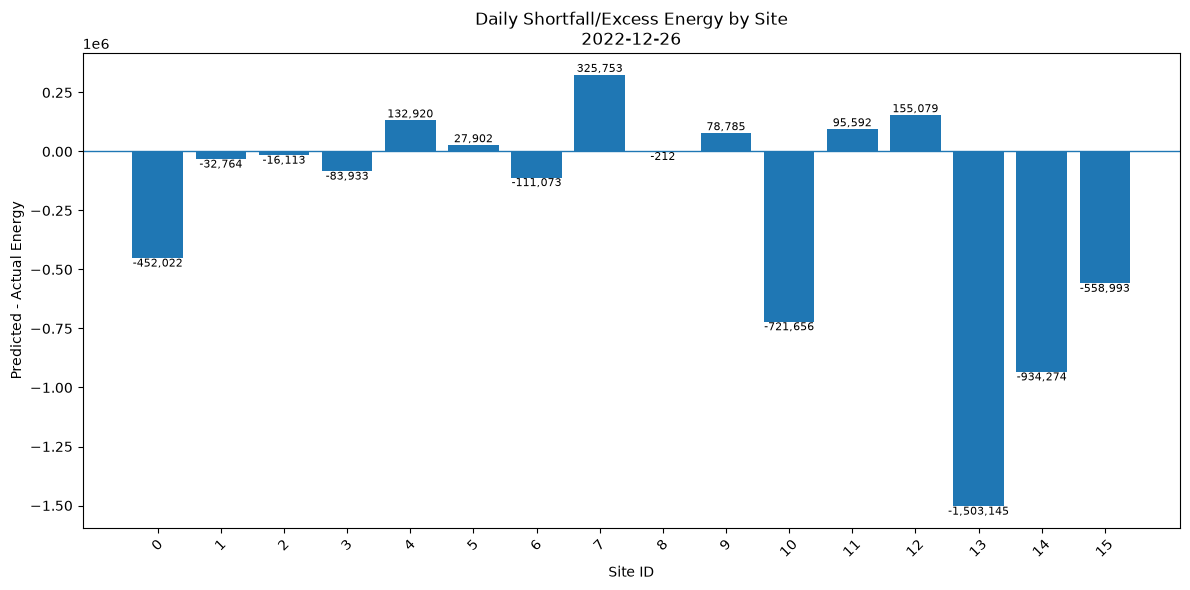

In [5]:
# ==============================
# 3. Daily shortfall/excess energy by site
# ==============================

# 3.1 Load building information to map building_id -> site_id
BUILDING_CSV = os.path.join(DATA_DIR, "new_building_information.csv")

building_info = pd.read_csv(BUILDING_CSV)

building_site = building_info[
    ["building_id", "site_id"]
].drop_duplicates()


# 3.2 Prepare actual meter data
actual = meters.copy()

actual["ts"] = pd.to_datetime(actual["ts"])
actual["date"] = actual["ts"].dt.date

# Add site_id to every meter record
actual = actual.merge(
    building_site,
    on="building_id",
    how="left"
)

# Sum all actual meter readings for each site and day
actual_site_daily = (
    actual
    .groupby(["site_id", "date"], as_index=False)["value"]
    .sum()
    .rename(columns={"value": "actual_energy"})
)


# 3.3 Prepare predicted daily energy from Kafka 6c
pred_site_daily = pd.DataFrame(latest_6c.values())

if pred_site_daily.empty:
    print("No 6c prediction data available. Run Q2 consumer first.")

else:
    pred_site_daily["date"] = pd.to_datetime(
        pred_site_daily["date"]
    ).dt.date

    pred_site_daily = (
        pred_site_daily[
            ["site_id", "date", "total_energy"]
        ]
        .rename(columns={
            "total_energy": "predicted_energy"
        })
    )


    # 3.4 Match predicted and actual data
    comparison = pred_site_daily.merge(
        actual_site_daily,
        on=["site_id", "date"],
        how="inner"
    )


    # 3.5 Calculate shortfall/excess
    comparison["shortfall_excess"] = (
        comparison["predicted_energy"]
        - comparison["actual_energy"]
    )


    print("Matched site-day records:", len(comparison))

    display(
        comparison.sort_values(
            ["date", "site_id"]
        ).head(20)
    )


    # 3.6 Plot latest available date
    if not comparison.empty:

        latest_date = comparison["date"].max()

        plot_df = (
            comparison[
                comparison["date"] == latest_date
            ]
            .sort_values("site_id")
        )

        plt.figure(figsize=(12, 6))

        bars = plt.bar(
            plot_df["site_id"].astype(str),
            plot_df["shortfall_excess"]
        )

        # Zero reference line
        plt.axhline(
            y=0,
            linewidth=1
        )

        # Value labels
        for bar, value in zip(
            bars,
            plot_df["shortfall_excess"]
        ):
            plt.text(
                bar.get_x() + bar.get_width() / 2,
                value,
                f"{value:,.0f}",
                ha="center",
                va="bottom" if value >= 0 else "top",
                fontsize=8
            )

        plt.xlabel("Site ID")
        plt.ylabel("Predicted - Actual Energy")
        plt.title(
            f"Daily Shortfall/Excess Energy by Site\n"
            f"{latest_date}"
        )

        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

    else:
        print(
            "No matching site and date between "
            "predicted and actual data."
        )

### Operational Interpretation

The chart shows both positive and negative differences between predicted and
actual daily energy consumption across sites. Positive values indicate that
predicted demand is higher than actual metered consumption, whereas negative
values indicate that the model underestimates actual demand.

In the displayed result, several sites show negative differences, with Site 13
showing the largest negative gap. This means that the actual metered energy
consumption at Site 13 was substantially higher than the model prediction for
that day. Conversely, sites with positive values represent cases where the
model predicted greater energy consumption than was actually recorded.

For a grid operator, underprediction may be particularly important because
actual demand can be greater than expected, potentially requiring additional
generation or reserve capacity. Large prediction errors should therefore be
monitored and investigated when forecasts are used to support operational
planning.

The difference between predicted and actual consumption does not by itself
identify its cause. Previous research shows that building energy prediction
can be affected by uncertainties in occupant behaviour, equipment and
operational schedules, building characteristics, weather conditions, and data
quality (Yu et al., 2022). Therefore, the large negative difference observed
for Site 13 may indicate operating conditions or consumption patterns that
were not fully captured by the model rather than a single identifiable cause.

4. Plot predicted vs. actual energy consumption over time for one building of your choice, and annotate/mark the point of largest prediction error. 

The purpose of this analysis is to examine how closely the model predictions follow actual metered energy consumption over time for one building and to identify the interval with the largest prediction error.

The prediction output from Task 6b represents energy consumption for each building within a 6-hour interval, whereas `new_meters.csv` contains meter readings at a finer timestamp level. Following the fixed-size window and granularity reduction concept discussed in Week 6a, the actual meter readings are aggregated into consecutive non-overlapping 6-hour intervals. Meter values within each interval are summed so that the predicted and actual data have the same granularity: **one building during one 6-hour interval**.

To avoid arbitrarily selecting a building, candidate buildings are evaluated based on the availability of matched predicted and actual observations and whether their average energy values are on a reasonably comparable scale. Buildings with at least 20 matched observations and a predicted-to-actual mean ratio between 0.5 and 2.0 are retained. Candidates are prioritised by the number of matched observations, followed by how close this ratio is to 1. This criterion supports a sufficiently complete and readable time-series comparison rather than selecting a building based on the smallest prediction error.

Before plotting, the matched timestamps are also checked for temporal gaps. A gap greater than the expected 6-hour interval indicates that consecutive observations are not temporally continuous. Connecting observations across such a gap would visually imply continuity where no matched observations are available. Therefore, the final visualisation uses the continuous segment containing the largest prediction error. This changes only the displayed time range; the underlying 6-hour granularity remains unchanged, and the largest error is calculated using all matched observations for the selected building.

Matched prediction-actual records: 629239

Top candidate buildings:


,building_id,matched_points,predicted_mean,actual_mean,scale_ratio
62,227,1440,92.365231,92.330306,1.000378
68,261,1440,938.531722,940.977521,0.997401
52,191,1440,1322.915340,1316.660523,1.004751
67,260,1440,1832.737598,1810.721983,1.012158
270,926,1440,481.344398,465.417388,1.034221
266,914,1440,8872.046610,8527.428906,1.040413
5,19,1440,726.332504,757.458727,0.958907
21,84,1440,94.669826,98.954988,0.956696
365,1171,1440,4078.643766,3843.112555,1.061287
13,61,1440,1028.294928,966.638817,1.063784



Selected Building 227: 1440 matched observations, predicted-to-actual mean ratio = 1.00

Temporal continuity check:
Number of gaps larger than 6 hours: 0

Displayed continuous period: 2022-01-01 00:00:00 to 2022-12-26 18:00:00
Observations displayed: 1440
Total matched observations for selected building: 1440


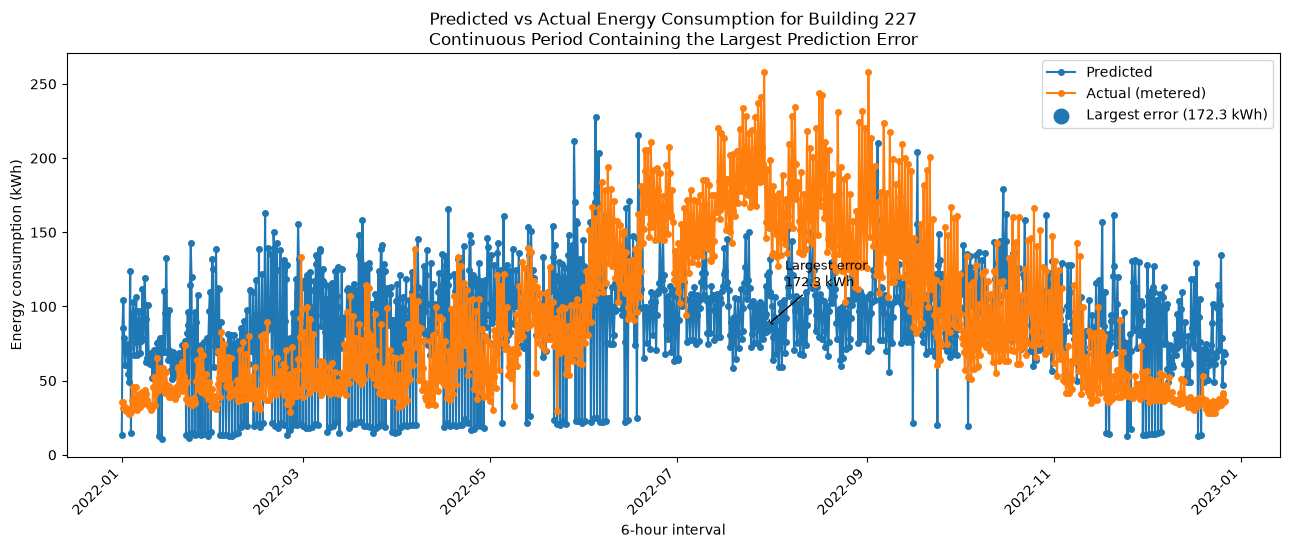


Largest prediction error
------------------------
Building ID: 227
Time: 2022-07-29 12:00:00
Predicted energy: 85.6 kWh
Actual energy: 257.9 kWh
Absolute error: 172.3 kWh


In [6]:
# ==============================
# 4. Predicted vs actual energy consumption for one building
# ==============================

# 4.1 Aggregate actual meter data to 6-hour intervals
actual_q4 = meters.copy()
actual_q4["ts"] = pd.to_datetime(actual_q4["ts"])

actual_q4["interval_start"] = (
    actual_q4["ts"].dt.floor("6h")
)

actual_building_6h = (
    actual_q4
    .groupby(
        ["building_id", "interval_start"],
        as_index=False
    )["value"]
    .sum()
    .rename(columns={"value": "actual_energy"})
)


# 4.2 Prepare predicted data from Task 6b
pred_q4 = pred_building.copy()

# Melbourne observes daylight saving, so interval_start strings carry
# different UTC offsets across the year (+11:00 in summer, +10:00 in
# winter). Parsing with utc=True handles that mix, then converting
# back to Australia/Melbourne and dropping the tz label recovers the
# original local wall-clock time so it matches actual_building_6h's
# naive timestamps.
pred_q4["interval_start"] = (
    pd.to_datetime(pred_q4["interval_start"], utc=True)
    .dt.tz_convert("Australia/Melbourne")
    .dt.tz_localize(None)
)

# Standardise prediction column name
if "predicted_energy" in pred_q4.columns:
    pred_q4 = pred_q4.rename(
        columns={"predicted_energy": "predicted_energy_q4"}
    )
elif "total_energy" in pred_q4.columns:
    pred_q4 = pred_q4.rename(
        columns={"total_energy": "predicted_energy_q4"}
    )


# 4.3 Match predicted and actual observations
comparison_q4 = pred_q4.merge(
    actual_building_6h,
    on=["building_id", "interval_start"],
    how="inner"
)

if comparison_q4.empty:
    raise ValueError(
        "No matching predicted and actual records were found."
    )

print(
    "Matched prediction-actual records:",
    len(comparison_q4)
)


# 4.4 Evaluate candidate buildings
building_summary = (
    comparison_q4
    .groupby("building_id")
    .agg(
        matched_points=("interval_start", "count"),
        predicted_mean=("predicted_energy_q4", "mean"),
        actual_mean=("actual_energy", "mean")
    )
    .reset_index()
)

# Ratio is used only to assess whether predicted and actual
# values are on a reasonably comparable scale for visualisation
building_summary["scale_ratio"] = (
    building_summary["predicted_mean"]
    / building_summary["actual_mean"].replace(0, pd.NA)
)

# Retain buildings with sufficient matched observations
# and reasonably comparable predicted/actual scales
candidates = (
    building_summary[
        (building_summary["matched_points"] >= 20)
        & (building_summary["scale_ratio"].between(0.5, 2.0))
    ]
    .copy()
)

if candidates.empty:
    raise ValueError(
        "No building satisfies the selection criteria."
    )

# Measure how close the predicted/actual mean ratio is to 1
candidates["distance_from_1"] = (
    candidates["scale_ratio"] - 1
).abs()

# Prioritise:
# 1. more matched observations
# 2. more comparable predicted/actual scales
candidates = candidates.sort_values(
    ["matched_points", "distance_from_1"],
    ascending=[False, True]
)

print("\nTop candidate buildings:")

display(
    candidates[
        [
            "building_id",
            "matched_points",
            "predicted_mean",
            "actual_mean",
            "scale_ratio"
        ]
    ].head(10)
)


# 4.5 Select the highest-ranked candidate
target_building = int(
    candidates.iloc[0]["building_id"]
)

selected = candidates.iloc[0]

print(
    f"\nSelected Building {target_building}: "
    f"{int(selected['matched_points'])} matched observations, "
    f"predicted-to-actual mean ratio = "
    f"{selected['scale_ratio']:.2f}"
)

building_q4 = (
    comparison_q4[
        comparison_q4["building_id"] == target_building
    ]
    .copy()
    .sort_values("interval_start")
)


# 4.6 Calculate prediction error using ALL matched observations
building_q4["abs_error"] = (
    building_q4["predicted_energy_q4"]
    - building_q4["actual_energy"]
).abs()

worst = building_q4.loc[
    building_q4["abs_error"].idxmax()
]


# 4.7 Detect temporal gaps
building_q4["time_difference"] = (
    building_q4["interval_start"].diff()
)

# Expected interval is 6 hours.
# A larger difference indicates a temporal gap.
building_q4["new_segment"] = (
    building_q4["time_difference"]
    > pd.Timedelta(hours=6)
)

building_q4["segment"] = (
    building_q4["new_segment"].cumsum()
)

# Show evidence of detected gaps
gaps = building_q4[
    building_q4["new_segment"]
][
    ["interval_start", "time_difference"]
]

print("\nTemporal continuity check:")
print("Number of gaps larger than 6 hours:", len(gaps))

if not gaps.empty:
    print("\nDetected gaps:")
    display(gaps.head(10))


# 4.8 Select the continuous segment containing the largest error
worst_segment = building_q4.loc[
    worst.name,
    "segment"
]

plot_q4 = (
    building_q4[
        building_q4["segment"] == worst_segment
    ]
    .copy()
    .sort_values("interval_start")
)

print(
    "\nDisplayed continuous period:",
    plot_q4["interval_start"].min(),
    "to",
    plot_q4["interval_start"].max()
)

print(
    "Observations displayed:",
    len(plot_q4)
)

print(
    "Total matched observations for selected building:",
    len(building_q4)
)


# 4.9 Plot predicted vs actual energy
plt.figure(figsize=(13, 6))

plt.plot(
    plot_q4["interval_start"],
    plot_q4["predicted_energy_q4"],
    marker="o",
    markersize=4,
    linewidth=1.5,
    label="Predicted"
)

plt.plot(
    plot_q4["interval_start"],
    plot_q4["actual_energy"],
    marker="o",
    markersize=4,
    linewidth=1.5,
    label="Actual (metered)"
)

# Highlight the prediction at the point with the largest error
plt.scatter(
    worst["interval_start"],
    worst["predicted_energy_q4"],
    s=110,
    zorder=5,
    label=f"Largest error ({worst['abs_error']:,.1f} kWh)"
)

plt.annotate(
    f"Largest error\n{worst['abs_error']:,.1f} kWh",
    xy=(
        worst["interval_start"],
        worst["predicted_energy_q4"]
    ),
    xytext=(15, 30),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->"),
    fontsize=9
)

plt.xlabel("6-hour interval")
plt.ylabel("Energy consumption (kWh)")

plt.title(
    f"Predicted vs Actual Energy Consumption "
    f"for Building {target_building}\n"
    f"Continuous Period Containing the Largest Prediction Error"
)

plt.xticks(rotation=45, ha="right")
plt.legend()
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()


# 4.10 Report largest prediction error
print("\nLargest prediction error")
print("------------------------")
print("Building ID:", target_building)
print("Time:", worst["interval_start"])

print(
    f"Predicted energy: "
    f"{worst['predicted_energy_q4']:,.1f} kWh"
)

print(
    f"Actual energy: "
    f"{worst['actual_energy']:,.1f} kWh"
)

print(
    f"Absolute error: "
    f"{worst['abs_error']:,.1f} kWh"
)

#### Focused View Around the Largest Prediction Error

The full-period visualisation contains 1,440 matched 6-hour observations.
Although it provides an overview of the prediction pattern across the entire
period, the high number of observations makes the largest prediction error
difficult to inspect visually.

Therefore, a focused time window around the largest error is displayed below.
Only the visualisation range is reduced; the underlying 6-hour granularity is
unchanged, and the largest error is still identified using all matched
observations.

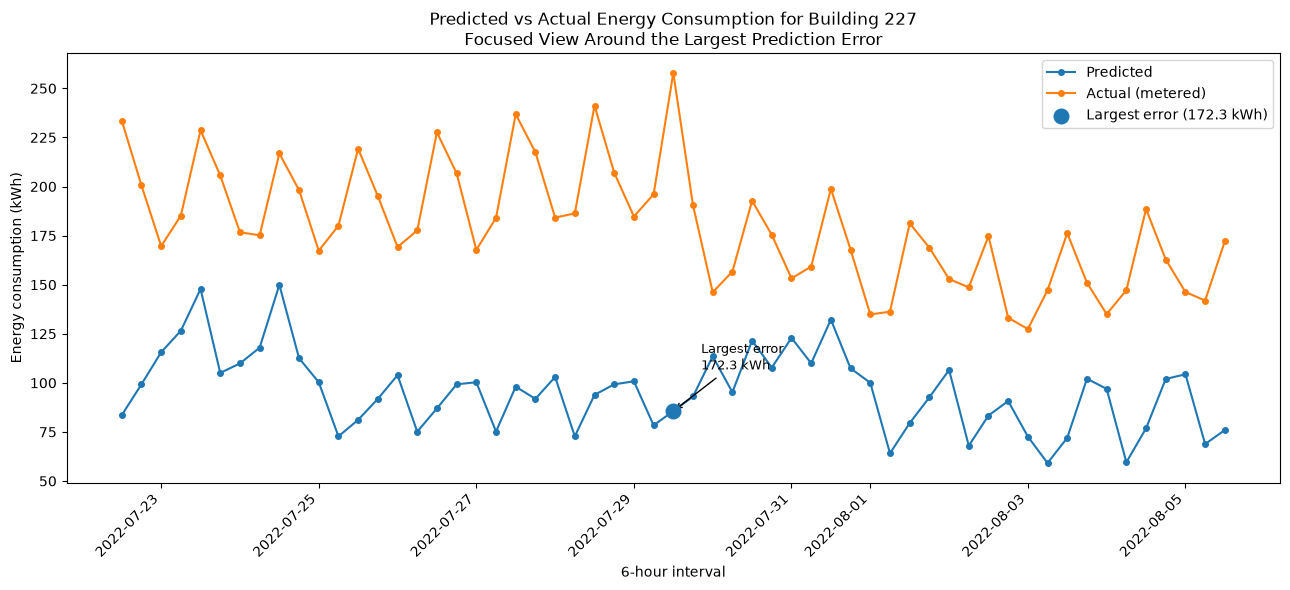

In [7]:
# Focused view around the largest prediction error

zoom_start = worst["interval_start"] - pd.Timedelta(days=7)
zoom_end = worst["interval_start"] + pd.Timedelta(days=7)

plot_zoom = building_q4[
    (building_q4["interval_start"] >= zoom_start)
    & (building_q4["interval_start"] <= zoom_end)
].copy()

plt.figure(figsize=(13, 6))

plt.plot(
    plot_zoom["interval_start"],
    plot_zoom["predicted_energy_q4"],
    marker="o",
    markersize=4,
    linewidth=1.5,
    label="Predicted"
)

plt.plot(
    plot_zoom["interval_start"],
    plot_zoom["actual_energy"],
    marker="o",
    markersize=4,
    linewidth=1.5,
    label="Actual (metered)"
)

plt.scatter(
    worst["interval_start"],
    worst["predicted_energy_q4"],
    s=110,
    zorder=5,
    label=f"Largest error ({worst['abs_error']:,.1f} kWh)"
)

plt.annotate(
    f"Largest error\n{worst['abs_error']:,.1f} kWh",
    xy=(
        worst["interval_start"],
        worst["predicted_energy_q4"]
    ),
    xytext=(20, 30),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->"),
    fontsize=9
)

plt.xlabel("6-hour interval")
plt.ylabel("Energy consumption (kWh)")
plt.title(
    f"Predicted vs Actual Energy Consumption for Building {target_building}\n"
    "Focused View Around the Largest Prediction Error"
)

plt.xticks(rotation=45, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

In [8]:
# ==============================
# 4.11 Check weather conditions around the largest error
# ==============================

weather_check = pd.read_csv(
    os.path.join(DATA_DIR, "weather.csv")
)

weather_check["timestamp"] = pd.to_datetime(
    weather_check["timestamp"]
)

weather_check["date"] = weather_check["timestamp"].dt.date

# Find the site of the automatically selected building
site_of_building = building_info.loc[
    building_info["building_id"] == target_building,
    "site_id"
].iloc[0]

# Date on which the largest prediction error occurred
worst_date = worst["interval_start"].date()

print("Selected building:", target_building)
print("Site:", site_of_building)
print("Largest-error date:", worst_date)

# Weather observations for the site on the error date
day_weather = weather_check[
    (weather_check["site_id"] == site_of_building)
    & (weather_check["date"] == worst_date)
]

display(
    day_weather[
        ["timestamp", "air_temperature", "dew_temperature"]
    ]
)

# Compare with overall temperature distribution for the same site
site_weather = weather_check[
    weather_check["site_id"] == site_of_building
]

print("\nTemperature distribution for this site:")
print(site_weather["air_temperature"].describe())

Selected building: 227
Site: 2
Largest-error date: 2022-07-29


,timestamp,air_temperature,dew_temperature
22566,2022-07-29 00:00:00,43.3,13.3
22567,2022-07-29 01:00:00,43.3,12.8
22568,2022-07-29 02:00:00,42.2,12.8
22569,2022-07-29 03:00:00,42.2,12.8
22570,2022-07-29 04:00:00,41.1,12.8
22571,2022-07-29 05:00:00,41.7,12.2
22572,2022-07-29 06:00:00,38.3,13.9
22573,2022-07-29 07:00:00,38.9,15.0
22574,2022-07-29 08:00:00,38.3,16.1
22575,2022-07-29 09:00:00,37.8,16.7



Temperature distribution for this site:
count    8782.000000
mean       24.940321
std         9.119835
min         2.200000
25%        17.800000
50%        25.600000
75%        32.200000
max        47.200000
Name: air_temperature, dtype: float64


### Interpretation

The selected building provides 1,440 matched predicted and actual observations,
with a predicted-to-actual mean ratio close to 1. This provides a complete
time-series comparison across the available period without selecting the
building based on prediction accuracy.

The largest prediction error occurs on 29 July 2022 at 12:00, when the model
predicts 85.6 kWh while the actual metered consumption reaches 257.9 kWh,
resulting in an absolute error of 172.3 kWh. The focused visualisation makes
this underprediction easier to observe while preserving the original 6-hour
granularity.

One plausible contributing factor is the relatively high temperature around
the error period. Building 227 belongs to Site 2, where the air temperature
was 35.0°C at 12:00 on the largest-error date, compared with the site's overall
mean temperature of approximately 24.9°C. Temperatures earlier on the same day
also exceeded 40°C. Outdoor temperature is recognised as an important factor
in building energy consumption and is commonly included in data-driven
building energy prediction models [1, 2].

This explanation is relevant to the model used in this study because
`air_temperature` and `dew_temperature` are included among its predictor
variables. However, the prediction error cannot be attributed to temperature
alone. Building energy consumption can also be affected by factors such as
occupancy, equipment use, and operational schedules that are not directly
represented by the available model features [1, 2]. Therefore, the observed
underprediction may reflect a combination of weather conditions and building
operating patterns that were not fully captured by the model.

#### References



Liu, H., Liang, J., Liu, Y., & Wu, H. (2023). A review of data-driven building energy prediction. Buildings, 13(2), 532. https://doi.org/10.3390/buildings13020532

Yu, J., Chang, W.-S., & Dong, Y. (2022). Building energy prediction models and related uncertainties: A review. Buildings, 12(8), 1284. https://doi.org/10.3390/buildings12081284

#### Generative AI Acknowledgement

We acknowledge the use of ChatGPT (OpenAI) and Claude during the development of this assignment. Both was used to assist with interpreting selected task requirements, explaining streaming and data-processing concepts, reviewing and debugging portions of Python/PySpark code, and improving the clarity of written explanations and code comments.

The generated suggestions were reviewed, tested, and modified before being incorporated into the final submission. All data processing, model outputs, visualisations, numerical results, and interpretations presented in the assignment were verified against the provided datasets, assignment requirements, and implemented code. 